<a href="https://colab.research.google.com/github/elbuh0/genai-course/blob/main/week5/lab/Week_5_Lab5_Multimodal_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 — Multimodal Storytelling Pipeline
**COM SCI-X 455 · Week 5 · Megan Armani, PhD**

> Push to `genai-course/week5/`  |  GPU: T4 required

---

## Setup — Run this first, models take ~10 min to download

In [2]:
!pip install -U torchao
!pip install git+https://github.com/suno-ai/bark.git scipy transformers accelerate openai gradio --quiet

import os
os.environ["SUNO_USE_SMALL_MODELS"] = "False"   # "True" = smaller/faster, lower quality
os.environ["SUNO_OFFLOAD_CPU"] = "False"        # "True" if you run out of GPU memory

import torch
print("GPU:", torch.cuda.is_available())

# Fix for PyTorch >= 2.6: allow Bark's official checkpoints to load
_orig_load = torch.load
torch.load = lambda *a, **k: _orig_load(*a, **{**k, "weights_only": False})

from bark import SAMPLE_RATE, generate_audio, preload_models
preload_models()   # ~5 GB download
print("Bark ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 28.9 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
GPU: True


text_2.pt: reconstructing file:   0%|          |  0.00B / 5.35GB            

text_2.pt: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

...

fine_2.pt: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Downloading: "https://dl.fbaipublicfiles.com/encodec/v0/encodec_24khz-d7cc33bc.th" to /root/.cache/torch/hub/checkpoints/encodec_24khz-d7cc33bc.th


100%|██████████| 88.9M/88.9M [00:00<00:00, 176MB/s]


Bark ready


In [3]:
import torch, numpy as np, os, time
from diffusers import StableDiffusionXLPipeline
from scipy.io.wavfile import write as wav_write
from openai import OpenAI
from PIL import Image
import matplotlib.pyplot as plt

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

# OpenAI client: key from Colab Secrets (key icon in left sidebar), optional
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("openai")
    client = OpenAI()
    print("OpenAI client ready")
except Exception as e:
    client = None
    print("No OpenAI key; API parts will be skipped:", type(e).__name__)

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Device: cuda
OpenAI client ready


## Part 1 — Bark TTS: Voice Generation for 3 Scenes



In [ ]:
# Your 3 scene scripts — customise these to your story theme
SCENES = [
    {"id": 1, "script": "Once upon a time, [deep breath] in a city where machines had learned to dream...", "voice": "v2/en_speaker_6"},
    {"id": 2, "script": "[music] The sky turned a thousand colours [gasps] as the first AI opened its eyes.", "voice": "v2/en_speaker_9"},
    {"id": 3, "script": "And somewhere in the code [laughs softly] — a new story had just begun.", "voice": "v2/en_speaker_3"},
]

import random
def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

audio_files = {}
for scene in SCENES:
    set_seed(42)                                   # reproducible take per scene
    t0 = time.time()
    audio = generate_audio(scene["script"], history_prompt=scene["voice"])
    duration = len(audio) / SAMPLE_RATE
    path = f"scene{scene['id']}_audio.wav"
    wav_write(path, SAMPLE_RATE, audio)
    audio_files[scene["id"]] = {"path": path, "duration": duration}
    print(f"Scene {scene['id']}: {duration:.1f}s audio generated in {time.time() - t0:.1f}s")

# Key measurement for sync
for sid, info in audio_files.items():
    print(f"Scene {sid}: {info['duration']:.2f}s - target FPS for 30-frame animation: {30 / info['duration']:.2f}")

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/usr/local/lib/python3.13/dist-packages/bark/generation.py:175: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with InferenceContext(), torch.inference_mode(), torch.no_grad(), autocast():
100%|██████████| 28/28 [00:38<00:00,  1.38s/it]


Scene 1: 11.2s audio generated in 120.3s


100%|██████████| 35/35 [00:47<00:00,  1.35s/it]


Scene 2: 13.6s audio generated in 64.7s


100%|██████████| 25/25 [00:34<00:00,  1.37s/it]


Scene 3: 9.9s audio generated in 47.9s
Scene 1: 11.16s - target FPS for 30-frame animation: 2.69
Scene 2: 13.63s - target FPS for 30-frame animation: 2.20
Scene 3: 9.89s - target FPS for 30-frame animation: 3.03


In [ ]:
from IPython.display import Audio, display
for sid, info in audio_files.items():
    print(f"Scene {sid}"); display(Audio(info["path"]))

Scene 1


Scene 2


Scene 3


Neither [deep breath] nor [music note] worked.

## Part 2 — SDXL Scene Illustration

In [ ]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16).to(DEVICE)

SCENE_PROMPTS = {
    1: {"prompt": "A cinematic wide shot of a futuristic city at twilight, machines glowing softly, dreamlike, digital painting",
        "negative": "blurry, people, crowds, text"},
    2: {"prompt": "Dramatic sky explosion of aurora colours, a single glowing robotic eye opening, photorealistic, epic lighting",
        "negative": "cartoon, low quality"},
    3: {"prompt": "Soft warm library interior, floating book of code, golden light, cosy and magical",
        "negative": "dark, scary, harsh"},
}

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

GPU in use before SDXL: 7.1 GB


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Scene 2: image saved to scene2_image.png in 23.7s


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Scene 3: image saved to scene3_image.png in 23.9s

=== Scene 1 ===


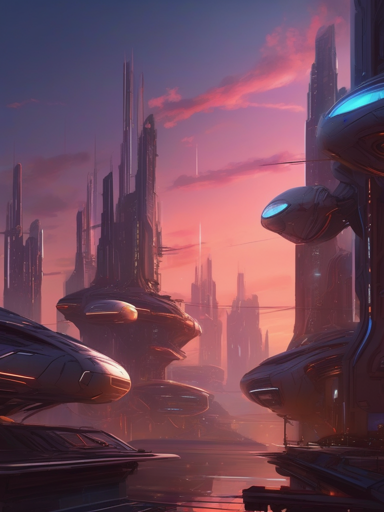


=== Scene 2 ===


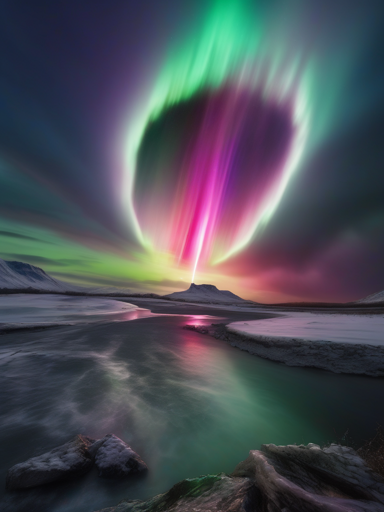


=== Scene 3 ===


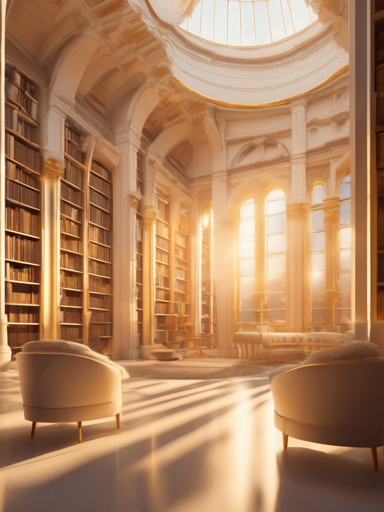

In [ ]:
# Generate one 768x1024 image per scene; save as scene{id}_image.png; pair with audio
import gc, sys, time, torch
from diffusers import StableDiffusionXLPipeline
from IPython.display import Audio, display

SEED, STEPS, CFG = 42, 30, 7.0
WIDTH, HEIGHT = 768, 1024          # portrait; swap for landscape

# Free Bark's models from the GPU (they're cached on disk; reload later if needed)
import bark.generation as bg
bg.clean_models()
sys.last_type = sys.last_value = sys.last_traceback = None
gc.collect(); torch.cuda.empty_cache()
print(f"GPU in use before SDXL: {torch.cuda.memory_allocated()/1e9:.1f} GB")   # want ~0

pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
pipe.to(torch.float16); pipe.to(DEVICE)            # explicit fp16 cast (avoids the fp32 OOM)
print(f"GPU after SDXL load: {torch.cuda.memory_allocated()/1e9:.1f} GB")      # ~7

SCENE_PROMPTS = {
    1: {"prompt": "A cinematic wide shot of a futuristic city at twilight, machines glowing softly, dreamlike, digital painting",
        "negative": "blurry, people, crowds, text"},
    2: {"prompt": "Dramatic sky explosion of aurora colours, a single glowing robotic eye opening, photorealistic, epic lighting",
        "negative": "cartoon, low quality"},
    3: {"prompt": "Soft warm library interior, floating book of code, golden light, cosy and magical",
        "negative": "dark, scary, harsh"},
}

image_files = {}
for sid, p in SCENE_PROMPTS.items():
    t0 = time.time()
    with torch.inference_mode():
        img = pipe(prompt=p["prompt"], negative_prompt=p["negative"],
                   width=WIDTH, height=HEIGHT, num_inference_steps=STEPS, guidance_scale=CFG,
                   generator=torch.Generator(DEVICE).manual_seed(SEED)).images[0]
    path = f"scene{sid}_image.png"
    img.save(path)
    image_files[sid] = path
    print(f"Scene {sid}: image saved to {path} in {time.time() - t0:.1f}s")

# Look at each image and listen to its audio
for sid in SCENE_PROMPTS:
    print(f"\n=== Scene {sid} ===")
    display(Image.open(image_files[sid]).resize((WIDTH // 2, HEIGHT // 2)))
    if sid in audio_files:
        display(Audio(audio_files[sid]["path"]))

#Are they tonally aligned? If not, document the mismatch — this is the modality mismatch failure mode.


They all seem largely tonally aligned to me; the last image was the most removed from the dialogue, but why couldn't a new story just begin in a sun-lit library, marble-collumned library?

## Part 3 — GPT-4o Story Generation + Streamlit App

In [13]:
# Generate a 3-scene story with GPT-4o in JSON mode, parse it, print narration + image prompt
import json

STORY_PROMPT = (
    'Create a 3-scene story about: A soldier\'s return from war, returning to a quiet life he leads dutiful; decades later, he dryly recalls: '
    '"So what if I was there? I don\'t remember a thing." Yet his tortured soul more than just '
    'remembers -it feels forever marked by, and marking of, that time, like a fly trapped in amber, or ice changed by the blood that stains it. '
    'Return JSON: {"scenes": [{"id":1, "title":"...", "narration":"...", "image_prompt":"..."}]}'
)

SYSTEM = (
    "You are a screenwriter. Respond only with valid JSON. Exactly 3 scenes. "
    "Each scene object has: id, title, mood, palette, narration, image_prompt, negative_prompt.\n"
    # Shared scene state: keeps audio and image aligned
    "mood: 3-5 words; palette: 3-5 colors. Both narration and image_prompt must express this same mood and palette.\n"
    # Narration rules: spoken by Bark TTS, which infers delivery from the text itself
    "narration: 25-35 words of literary narration, read like the opening of a serious novel. "
    "Complete, flowing sentences in past tense, plain and restrained. At most one '...' pause per scene. "
    "No fragments, no lists of short phrases, no exclamations, no bracketed cues, no 'Once upon a time'. "
    "Concrete specifics (a year, a job, an object) instead of vague moods. "
    "The final scene must include his quoted line: 'So what if I was there? I don't remember a thing.' "
    "Example of the right register: 'He came home in the autumn of 1972, and the town had not changed. "
    "He took work at the mill, married, and kept the lawn neat. He never spoke of the war.'\n"
    # Image rules: SDXL reads words as visual concepts, max 77 tokens
    "image_prompt: under 50 words. Describe only what a camera could see: subject first, then setting, lighting, colors, composition. "
    "Never use metaphors, emotions, or abstract nouns; translate them into visible details "
    "(e.g. 'haunted' -> 'hollow stare, untouched coffee'). Never use negations. "
    "End with shot type and style, e.g. 'medium shot, 35mm film photo, muted colors'. "
    "Keep the soldier's appearance consistent across scenes, aging him as the story moves through decades.\n"
    "negative_prompt: comma-separated things to exclude, including any literal rendering of metaphors from the story "
    "(e.g. insects, amber tint, blood) plus 'text, watermark, cartoon, blurry'."
)

if client is None:
    raise RuntimeError("No OpenAI client: add OPENAI_API_KEY in Colab Secrets and rerun the imports cell.")

response = client.chat.completions.create(
    model="gpt-4o",
    response_format={"type": "json_object"},
    messages=[{"role": "system", "content": SYSTEM},
              {"role": "user", "content": STORY_PROMPT}],
    temperature=0.7,
)

raw = response.choices[0].message.content
try:
    story = json.loads(raw)
except json.JSONDecodeError as e:
    print("Model returned invalid JSON:\n", raw)
    raise e

story_scenes = story.get("scenes", [])
assert len(story_scenes) == 3, f"Expected 3 scenes, got {len(story_scenes)}"

for s in story_scenes:
    n_words = len(s["narration"].split())
    print(f"\n=== Scene {s['id']}: {s.get('title', '')} ===")
    print("Mood / palette: ", s.get("mood", ""), "|", s.get("palette", ""))
    print(f"Narration ({n_words} words):", s["narration"])
    print("Image prompt:   ", s["image_prompt"])
    print("Negative prompt:", s.get("negative_prompt", ""))


=== Scene 1: Homecoming, 1972 ===
Mood / palette:  quiet, dutiful, resigned | sepia, olive green, faded blue
Narration (36 words): He returned in the fall of 1972, the town unchanged since he'd left. He found work at the factory, wore a tie each day, and mowed the lawn every Saturday. He never spoke of the war.
Image prompt:    A middle-aged man in a crisp white shirt stands on the porch of a small house. Fallen leaves scatter the yard. The sky is overcast, casting a soft shadow. Medium shot, 35mm film photo, muted colors.
Negative prompt: smiling, children, bright sunlight, text, watermark, cartoon, blurry

=== Scene 2: Years of Routine ===
Mood / palette:  monotonous, subdued, persistent | gray, beige, dull green
Narration (31 words): Through the years, he rose with the dawn and worked the day away. The factory's hum became a familiar lullaby. Evenings, he read papers in a worn armchair, silence his companion.
Image prompt:    An older man, gray-haired, sits in a dimly lit living ro

In [14]:
import gc, json, random, time, torch, numpy as np
from scipy.io.wavfile import write as wav_write

VOICE = "v2/en_speaker_6"      # replace with the gravest preset from your audition
SEED = 42
TEXT_TEMP, WAVE_TEMP = 0.6, 0.6   # lower = steadier, less animated delivery (default 0.7)
DEFAULT_NEG = "blurry, low quality, text, watermark, cartoon"

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# Save story text for the app
json.dump(story_scenes, open("story.json", "w"), indent=2)

# 1) Audio with Bark (free SDXL first)
globals().pop("pipe", None); gc.collect(); torch.cuda.empty_cache()
import torch.serialization
_real_torch_load = torch.serialization.load          # PyTorch's untouched original
torch.load = lambda *a, **k: _real_torch_load(*a, **{**k, "weights_only": False})
from bark import SAMPLE_RATE, generate_audio, preload_models
import bark.generation as bg
preload_models()

audio_files = {}
for s in story_scenes:
    set_seed()
    t0 = time.time()
    audio = generate_audio(s["narration"], history_prompt=VOICE,
                           text_temp=TEXT_TEMP, waveform_temp=WAVE_TEMP)
    path = f"scene{s['id']}_audio.wav"
    wav_write(path, SAMPLE_RATE, audio)
    audio_files[s["id"]] = {"path": path, "duration": len(audio) / SAMPLE_RATE}
    print(f"Scene {s['id']}: {audio_files[s['id']]['duration']:.1f}s audio in {time.time() - t0:.1f}s")

# 2) Images with SDXL (free Bark first)
bg.clean_models(); gc.collect(); torch.cuda.empty_cache()
from diffusers import StableDiffusionXLPipeline
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
pipe.to(torch.float16); pipe.to(DEVICE)

for s in story_scenes:
    neg = s.get("negative_prompt") or DEFAULT_NEG          # per-scene negative from GPT-4o
    t0 = time.time()
    with torch.inference_mode():
        img = pipe(prompt=s["image_prompt"], negative_prompt=neg,
                   width=768, height=1024, num_inference_steps=30, guidance_scale=7.0,
                   generator=torch.Generator(DEVICE).manual_seed(SEED)).images[0]
    img.save(f"scene{s['id']}_image.png")
    print(f"Scene {s['id']}: image in {time.time() - t0:.1f}s  | negative: {neg}")

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/usr/local/lib/python3.13/dist-packages/bark/generation.py:175: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with InferenceContext(), torch.inference_mode(), torch.no_grad(), autocast():
100%|██████████| 33/33 [00:45<00:00,  1.38s/it]


Scene 1: 13.2s audio in 62.6s


100%|██████████| 37/37 [00:49<00:00,  1.35s/it]


Scene 2: 14.6s audio in 70.0s


100%|██████████| 31/31 [00:41<00:00,  1.35s/it]


...

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Scene 2: image in 24.1s  | negative: laughing, family, bright colors, text, watermark, cartoon, blurry


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Scene 3: image in 22.4s  | negative: tears, bright light, vibrant colors, text, watermark, cartoon, blurry


In [15]:
STREAMLIT_APP = '''
import json
import streamlit as st
from pathlib import Path

st.set_page_config(page_title="AI Storybook", layout="wide")
st.title("AI Multimodal Storybook")
st.caption("Generated with GPT-4o · SDXL · Bark")

scenes = json.loads(Path("story.json").read_text()) if Path("story.json").exists() else []

for i in range(1, 4):
    scene = next((s for s in scenes if s.get("id") == i), {})
    st.subheader(f"Scene {i}: {scene.get('title', '')}")
    col1, col2 = st.columns([1, 1])
    with col1:
        img_path = f"scene{i}_image.png"
        if Path(img_path).exists():
            st.image(img_path)
        else:
            st.warning(f"{img_path} not found")
    with col2:
        if scene.get("narration"):
            st.write(scene["narration"])
        audio_path = f"scene{i}_audio.wav"
        if Path(audio_path).exists():
            st.audio(audio_path)
        else:
            st.warning(f"{audio_path} not found")
    st.divider()
'''
with open("storybook_app.py", "w") as f:
    f.write(STREAMLIT_APP)
print("storybook_app.py saved")

storybook_app.py saved


In [16]:
!pip install streamlit --quiet
!pkill -f "streamlit run"
import subprocess, time
proc = subprocess.Popen(["python", "-m", "streamlit", "run", "storybook_app.py", "--server.port", "8503",
                         "--server.headless", "true",
                         "--server.enableCORS", "false", "--server.enableXsrfProtection", "false"],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(8)
print("running" if proc.poll() is None else proc.stdout.read())

!pkill -f "streamlit run"
import subprocess, time
proc = subprocess.Popen(["streamlit", "run", "storybook_app.py", "--server.port", "8503",
                         "--server.headless", "true",
                         "--server.enableCORS", "false", "--server.enableXsrfProtection", "false"],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(8)
print("running" if proc.poll() is None else proc.stdout.read())
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8503)"))

running
running
https://8503-gpu-t4-s-usw4a2-3pmdosea3josj-a.us-west4.prod.r.colab.dev


### ❓ Reflect
1. Which Bark non-speech cues worked? Which were spoken literally? Name the failure mode.
2. Scene 1 image vs audio — were they aligned? If not, what specifically was misaligned?
3. ElevenLabs charges $0.30/1K chars. For a 500-lesson ed-tech platform at 150 words/lesson: calculate total cost vs Bark. What other factors matter?
4. What one architecture change would most improve cross-modal alignment in your pipeline?

1. Only laughter worked. Breath was non-human and raspy; music notes played, but the remainder of the sentence was rapidly stated in a quasi sing-songy way that also garbeled. The first failure mode appears to be a misrendering. The second could be that the cue to create musical notes carried over into the subsequent clause, rendering it rhythmically more like music.
2. They were all relatively well aligned, with the exception of frankly ameteaurish or flippant tones that were tonally discorndant with the gravity of the emmergence of super intelligence.
3. Calculations:
Lessons: 500
Words per lesson: 150
Total words: 500 * 150 = 75,000
Estimated characters: roughly 5 - 6 characters per word, including spaces
Estimated total characters / pricing: [375,000 - 450,000 / (1000)]*.30 = 112.50 - 135
5. Bark never sees the image prompt, and SDXL never sees the narration or hears the audio. One change to improve cross-modal alignment would be to have GPT-4o output one shared output requirement (describing for example mood, setting, palette, character) from which both the narration and the image prompt are built. This way the two models work from the same single source of output requirements.

Relection: Pipeline Failure Analysis

1. Look at your generated image and listen to your Bark narration for the same scene. Are they tonally and semantically aligned? If not describe the mismatch specifically and explain which of the four multi-modal failure modes from the lecture this represents.

1.1. They were overall aligned, though the voice seemed a bit flippant frankly considering the gravity of the story's emergence of super intelligence. This modality mismatch failure mode. As the first output did not condition the other, there was a mismatch. Even if that was fixed, you'd still need to adjust Bark's prompt and insert non-verbal cues to improve the flippant pod-caster type voice discussing the horrors of war.

2. Bark generates audio of variable duration - your scenes may be 2.1s, 4.8s, and 3.3s. If you were adding video/animation to this story book describe exactly how you would synchronize image display duration to audio duration. What variables control this? Write the pseudocode.

2.1. The variables that control this would be len(audio_array), sample_rate, and frames-per-second (FPS). Dividing len(audio_array) by Bark's sample_rate of 24,000 would yield the audio duration in seconds. That result would in turn define a new variable, e.g., display_duration, which multiplied by FPS determines how many frames the image is shown for (n_frames = display_duration * FPS):

SAMPLE_RATE = 24000   # Bark's sample rate
FPS = 24   # frames per second

for each scene:
    
audio_duration = len(audio_array) / SAMPLE_RATE.   # seconds
display_duration = audio_duration
n_frames = display_duration * FPS   # frames the image is shown for

show scene image for n_frames
play scene audio at the same time

3. You used GPT-4o to generate image prompts for SDXL. GPT-4o doesn't know what SDXL responds well to. Describe one specific failure you can imagine where the GPT-4o generated prompt produced a poor SDXL image, and propose a prompt engineering fix.

One failure mode I can imagine is that metaphors such as my prompt's description of the weary soldier describing his inexorable attachment to the time and place of his trauma as "firmly caught in [it] like a fly in amber" are inadequately or worse literally rendered. The fix would be to provide more concretely descriptive prompts avoiding pure metaphors.

4. ElevenLabs charges $.30 per 1K characters. Bark is free. For a commercial audiobook narration product with 80k characters of content calculate the cost difference. What other factors (quality latency API reliability voice consistency) would you weigh in making the decision?

I would spring for ElevenLabs, even if it cost about $130 a book to narrate. Quality is key: Unless the business model is to undercut everyone in the business, and you pass those savings on to an accordingly more tolerant-of-faults, thrifty user, then it's important to render non-verbal cues, tone, and metaphors precisely to ensure seamless narrative immersion. I would expect latency and API reliability would be good with ElvenLabs as well, since it's their whole business afterall and you can hold their feet to the fire if need be.